#### Load Packages

In [2]:
suppressMessages(library(tidyverse))

source("./Manuscript_files/theme_ggplot_cfrna.R")

custom_colors <- c('#6EA4BF','#688E26', '#FAA613', 'gray60', '#A491D3', '#D1495B',  '#55D6BE','#C1747C', '#AEBBE6', '#92158B', '#F76716', '#6F392B')

#### Plotting Code

In [3]:
# READ IN FILES
samples <- read.delim("./Manuscript_files/sample_metadata.tsv")
all_braken_df <- read.delim("/workdir/aeg267/ME_CFS/02_Scripts/Manuscript_files/metagenome_counts.tsv")

In [4]:
## VIRAL: REMOVE BACKGROUND COUNTS
king_donor_background = c("Siphoviridae", "Baculoviridae", "Tospoviridae", "Autographiviridae", "Alphaflexiviridae", "Virgaviridae", "Tymoviridae",
                         "Bromoviridae", "Myoviridae", "Solemoviridae", "Genomoviridae", "Endornaviridae", "Tombusviridae", "Casjensviridae", 
                         "Herelleviridae", "Chrysoviridae", "Phycodnaviridae", "Straboviridae", "Potyviridae", "Marnaviridae")
                                        
# Filter and group by family/genus
viral_by_family_df <- all_braken_df %>% 
  filter(superkingdom == "Viruses") %>%
  filter(!(family %in% king_donor_background)) %>%
  group_by(sample_id_0, family, genus) %>%
  summarize(sum_cnts = sum(new_est_reads), .groups = "drop") %>%
  left_join(samples %>% select(sample_id_0, align_input), by = "sample_id_0") %>%
  mutate(sum_cnts_cpm = log10(((sum_cnts / align_input) * 1e6) + 1))

In [5]:
# Get top families
top_families <- viral_by_family_df %>%
  group_by(family) %>%
  summarize(total_cpm = sum(sum_cnts_cpm), .groups = "drop") %>%
  filter(family != "missing", family != "Autographiviridae") %>%
  arrange(desc(total_cpm)) %>%
  mutate(family = ifelse(row_number() <= 6, as.character(family), "Other")) %>%
  group_by(family) %>%
  summarize(total_cpm = sum(total_cpm), .groups = "drop") %>%
  arrange(desc(total_cpm)) %>%
  mutate(family = factor(family, levels = unique(family)))

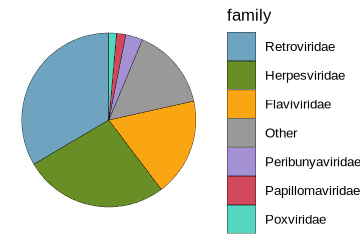

In [6]:
# SUM VIRAL COUNTS BY FAMILY
width = 3
height = 2
options(repr.plot.width = width, repr.plot.height = height)

plot_name <- "mammalian_pie"

plot_me <- ggplot(top_families, aes(x = "", y = total_cpm, fill = family)) +
  geom_bar(width = 0.25, stat = "identity", color = "black", linewidth = 0.1) +
  coord_polar(theta = "y") +
  theme_void() +
  theme(legend.position = "right", text = element_text(size = 10)) +
  scale_fill_manual(values = custom_colors)

plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_5/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)

In [7]:
# Total viral counts by sample
viral_total_df <- all_braken_df %>% 
  filter(!(family %in% king_donor_background)) %>%
  group_by(sample_id_0, superkingdom) %>%
  summarize(sum_cnts = sum(new_est_reads), .groups = "drop") %>%
  filter(superkingdom == "Viruses") %>%
  left_join(samples, by = "sample_id_0") %>%
  mutate(sum_cnts_cpm = log10(((sum_cnts / align_input) * 1e6) + 1))

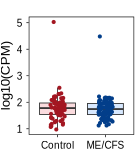

In [8]:
# SUM VIRAL COUNTS
width = 1.125
height = 1.25

options(repr.plot.width = width, repr.plot.height = height)

plot_name <- "viral_SUM"

plot_me <- viral_total_df %>%
  mutate(pre_post_cpet = factor(pre_post_cpet)) %>%
  ggplot(aes(x = phenotype, y = sum_cnts_cpm, fill = phenotype)) +
  geom_boxplot(width = 0.75, outlier.shape = NA, lwd = 0.25) +
  geom_jitter(aes(color = phenotype),
              position = position_jitterdodge(jitter.width = 0.3),
              alpha = 1, size = 0.5) +
  scale_color_manual(values = COLORS) +
  scale_fill_manual(values = COLORS_FILL) +
  scale_x_discrete(labels = c("HC" = "Control", "MECFS" = "ME/CFS")) +
  theme_cfrna_paper() +
  labs(title = " ", x = NULL, y = "log10(CPM)") +
  theme(plot.title = element_text(size = 4))

plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_5/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)

In [9]:
# Create count matrix of top 6 viral families
get_families_counts <- function(SAMP, DF, FAMs){
    tmp <- DF %>% 
        filter(sample_id_0 == SAMP) %>%  
        group_by(family) %>%
        summarize(num_reads = sum(new_est_reads), .groups = "drop") %>% 
        filter(family %in% FAMs) %>% 
        column_to_rownames("family") %>% 
        t() %>% data.frame() %>% 
        mutate(sample_id_0 = SAMP) %>% remove_rownames()

    INT_COLS <- c(FAMs, "sample_id_0")
    for (i in setdiff(INT_COLS, colnames(tmp))) {
        tmp[, i] <- 0
    }

    return(tmp %>% relocate(sample_id_0))
}

In [10]:
# Summarize family-level abundance
top_viruses <- viral_by_family_df %>% 
    group_by(family) %>% 
    summarize(sum_cnts = sum(sum_cnts_cpm), .groups = "drop") %>%
    arrange(desc(sum_cnts))

# Define top viral families for downstream plots
VIRAL_fams <- top_viruses %>% 
    filter(family != "missing", family != "Autographiviridae") %>%
    pull(family) %>% head(3) %>%
    union("Picornaviridae")  # Add manually even if not in top 3


In [11]:
# Apply to all samples
all_fams_df <- lapply(samples$sample_id_0, get_families_counts, all_braken_df, VIRAL_fams)
all_fams_df <- do.call(rbind, all_fams_df) %>% data.frame()

# Melt and clean
all_fams_df <- all_fams_df %>% 
    reshape2::melt(id.vars = "sample_id_0") %>% 
    dplyr::rename(viral_fam = variable, new_est_reads = value) %>%
    mutate(new_est_reads = as.numeric(new_est_reads))

# Ensure align_input is numeric
samples <- samples %>%
    mutate(align_input = as.numeric(align_input))

# Merge and normalize
all_fams_df <- merge(all_fams_df, samples, by = "sample_id_0") %>% 
    select(sample_id_0, phenotype, pre_post_cpet, lib_prep_date, align_input, viral_fam, new_est_reads) %>% 
    mutate(sum_cnts_cpm = log10(((new_est_reads / align_input) * 1e6) + 1)) %>%
    mutate(viral_fam = factor(viral_fam, levels = VIRAL_fams))

# Focus on top 4 for plot
all_fams_df <- all_fams_df %>%
    mutate(viral_fam = factor(viral_fam, levels = c("Flaviviridae", "Herpesviridae", "Retroviridae", "Picornaviridae")))

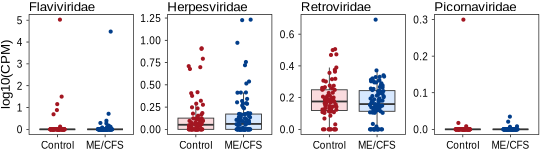

In [12]:
# TOP 3 VIRAL FAMILIES AND PICORNAVIRIDAE
width <- 4.5
height <- 1.25
options(repr.plot.width = width, repr.plot.height = height)

plot_name <- "viral_top4"

plot_me <- all_fams_df %>%
    ggplot(aes(x = phenotype, y = sum_cnts_cpm, fill = phenotype)) +  
    geom_boxplot(width = 0.75, outlier.shape = NA, lwd = 0.25) + 
    geom_jitter(aes(color = phenotype), position = position_jitterdodge(jitter.width = 0.3), alpha = 1, size = 0.5) +
    scale_color_manual(values = COLORS) +
    scale_fill_manual(values = COLORS_FILL) +
    scale_x_discrete(labels = c("HC" = "Control", "MECFS" = "ME/CFS")) +
    theme_cfrna_paper() +
    labs(title = NULL, x = NULL, y = "log10(CPM)") +
    facet_wrap(~viral_fam, scales = "free_y", nrow = 1) +
    theme(strip.background = element_blank(), strip.text = element_text(hjust = 0, margin = margin(b = 1))) 

plot_me

# Save to PDF
ggsave(paste0("./Figure_outputs/figure_5/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)